# Evaluación 1 grupal del proyecto — CRISP-DM

## Brecha de acceso a Internet en viviendas de La Paz

**Grupo: ROCKY**  
**Materia:** Minería de Datos  
**Docente:** Ing. Enrique Alejandro Laurel Cossio

**Integrantes:**
- Galilea Alison Llusco Asistiri
- Alex Quispe Ticona
- Alejandro Villalpando Rojas
- Cristopher Iori Lazcano Gutierrez
- Limber Soto Cazu


Este notebook responde las **diez preguntas** de la rúbrica de la materia y reproduce
las fases 1–4: negocio, datos, preparación y modelado. El modelo principal de esta
evaluación es la **regresión logística**, permitido por la rúbrica; el árbol se entrega
por separado en la tarea 2. Todas las cifras se calculan aquí desde los microdatos,
sin resultados incrustados ni archivos de métricas precalculadas.

**Cómo ejecutar:** Python con pandas, NumPy, Matplotlib, scikit-learn y openpyxl.
Colocar `Vivienda_CPV-2024.csv` y `Diccionario de variables CPV 2024.xlsx` en
`Base de datos CSV/`, junto al notebook o en la raíz del repositorio. Ejecutar todas
las celdas en orden. También puede indicarse una carpeta en `CARPETA_DATOS`.
El notebook es independiente de `src/` y no descarga datos.

**Referencia:** [rúbrica del docente, versión proporcionada](https://github.com/ealaurel/MINERIA_DATOS_2026_2/blob/615ea6ef4d0ad741ff59f3d32a4cfa47a7607339/evaluacion1_grupal_proyecto_crisp_dm.md).
Los resultados describen acceso declarado en 2024; no miden velocidad, calidad ni causalidad.


**Organización:** cada pregunta con evidencia cuantitativa se presenta como pregunta, código ejecutado y respuesta textual en Markdown. La pregunta 1 define el problema y el criterio de negocio de forma conceptual.

In [1]:
from pathlib import Path
import hashlib, re, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import Markdown, display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
    classification_report)

CARPETA_DATOS = None  # Opcional: Path('ruta/a/Base de datos CSV')
SEMILLA = 777
FUENTE = 'Fuente: microdatos Vivienda, Censo 2024; cálculo del grupo ROCKY.'
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
pd.set_option('display.max_colwidth',100)
print('Python:',sys.version.split()[0],'| pandas:',pd.__version__,
      '| NumPy:',np.__version__,'| scikit-learn:',sklearn.__version__)


Python: 3.12.10 | pandas: 3.0.5 | NumPy: 2.5.2 | scikit-learn: 1.9.1


## 1. ¿Qué problema aborda el proyecto, qué decisión apoya y cuál es el criterio de éxito?

### Respuesta 1

La brecha de acceso a Internet en viviendas de La Paz puede limitar educación,
comunicación y acceso a servicios. El análisis busca apoyar la **priorización de
territorios para diagnóstico de conectividad** y describir perfiles asociados al acceso.
No decide por sí solo qué hogares reciben apoyo: requiere verificación territorial,
costos y disponibilidad de infraestructura.

El criterio de negocio propuesto es elevar la cobertura de los territorios priorizados
al comparar mediciones con el mismo universo. No se midió ninguna intervención ni
se afirma una mejora real de cobertura. Para esta primera iteración, el criterio técnico
es superar la clasificación mayoritaria en prueba, mostrar ROC-AUC y examinar los
errores que ocultan viviendas sin conexión.

## 2. ¿Cuál es la métrica principal y cómo se calcula?

In [2]:
if CARPETA_DATOS is None:
    candidatos=[p/'Base de datos CSV' for p in [Path.cwd(),*Path.cwd().parents]]
    CARPETA_DATOS=next((p for p in candidatos if (p/'Vivienda_CPV-2024.csv').is_file()),None)
if CARPETA_DATOS is None:
    raise FileNotFoundError('Colocar los dos originales en Base de datos CSV o indicar CARPETA_DATOS.')
CARPETA_DATOS=Path(CARPETA_DATOS)
archivo=CARPETA_DATOS/'Vivienda_CPV-2024.csv'
diccionario_path=CARPETA_DATOS/'Diccionario de variables CPV 2024.xlsx'
columnas=['idep','iprov','imun','i00','urbrur','v01_tipoviv','v02_condocup',
          'v09_energia','v13_habitac','v14_dormit','v19c_compu','v19d_celular',
          'v19e_inetfijo','v19f_inetmovil','v19e_f','tot_pers']
encabezado=pd.read_csv(archivo,sep=';',encoding='utf-8-sig',nrows=0).columns
assert set(columnas).issubset(encabezado)
partes=[]; registros_nacionales=0
for bloque in pd.read_csv(archivo,sep=';',encoding='utf-8-sig',usecols=columnas,
                         dtype='string',keep_default_na=False,chunksize=200_000):
    registros_nacionales+=len(bloque)
    partes.append(bloque.loc[bloque.idep.eq('02'),columnas].copy())
lapaz=pd.concat(partes,ignore_index=True)
del partes,bloque
aplicable=lapaz.v01_tipoviv.isin(['1','2','3','4','5','6']) & lapaz.v02_condocup.isin(['0','1'])
universo=lapaz.loc[aplicable].copy()
conteos=universo.v19e_f.value_counts()
si,no,sin_especificar=[int(conteos.get(c,0)) for c in ['1','2','9']]
assert si+no+sin_especificar==len(universo)
cobertura=100*si/len(universo)
display(pd.DataFrame([{'Universo TIC (viviendas)':len(universo),'Con Internet':si,
    'Sin Internet':no,'Sin especificar':sin_especificar,'Cobertura (%)':cobertura,
    'Cobertura entre Sí/No (%)':100*si/(si+no)}]).round(4))
display(Markdown(f'**Valor observado:** {si:,} / {len(universo):,} × 100 = **{cobertura:.2f}%**.'))
print(FUENTE)


,Universo TIC (viviendas),Con Internet,Sin Internet,Sin especificar,Cobertura (%),Cobertura entre Sí/No (%)
0,1069838,748401,290940,30497,69.9546,72.0073


**Valor observado:** 748,401 / 1,069,838 × 100 = **69.95%**.

Fuente: microdatos Vivienda, Censo 2024; cálculo del grupo ROCKY.


### Respuesta 2

La métrica de negocio es **cobertura de algún Internet declarado**:

$$\mathrm{Cobertura}(\%)=100\,\frac{N(v19e\_f=1)}{N(\mathrm{universo\ TIC})}.$$

El universo TIC incluye viviendas particulares (tipos 1–6) con personas presentes
(ocupación 0/1). Los conteos son viviendas. El código 9, «sin especificar», permanece
en el denominador, pero no cuenta como acceso ni como ausencia determinada.
Se presenta también Sí/(Sí+No) para revisar sensibilidad a la no respuesta.
La cobertura se distingue de accuracy, que mide aciertos del modelo.
La acción futura propuesta es identificar territorios rezagados, verificar condiciones
del servicio y diseñar un piloto con medición anterior y posterior comparable.

**Resultado observado:** 748.401 viviendas con Internet entre 1.069.838 viviendas del universo TIC: **69,95%**. Hay 290.940 viviendas sin Internet y 30.497 respuestas sin especificar. Si se consideran únicamente respuestas Sí/No, la proporción con Internet es **72,01%**; esta medida usa un denominador distinto y no reemplaza la cobertura principal.

## 3. ¿Cuál es la unidad de análisis, la fuente y las dimensiones?

In [3]:
valido=aplicable & lapaz.v19e_f.isin(['1','2'])
display(pd.DataFrame([
 ['CSV nacional original',registros_nacionales,len(encabezado)],
 ['Selección La Paz',len(lapaz),len(columnas)],
 ['Universo TIC',len(universo),len(columnas)],
 ['Clasificación (7 predictores y target)',int(valido.sum()),8]
],columns=['Conjunto','Registros (viviendas)','Variables']))
display(pd.Series({'Fuera del universo TIC':int((~aplicable).sum()),
                   'Target sin especificar':sin_especificar},name='Exclusiones').to_frame())
def huella(p):
    h=hashlib.sha256()
    with p.open('rb') as f:
        for b in iter(lambda:f.read(8*1024*1024),b''):h.update(b)
    return h.hexdigest()
display(pd.DataFrame([{'Archivo':p.name,'Bytes':p.stat().st_size,'SHA-256':huella(p)}
                      for p in [archivo,diccionario_path]]))
print(FUENTE)


,Conjunto,Registros (viviendas),Variables
0,CSV nacional original,4490488,48
1,Selección La Paz,1334496,16
2,Universo TIC,1069838,16
3,Clasificación (7 predictores y target),1039341,8


,Exclusiones
Fuera del universo TIC,264658
Target sin especificar,30497


,Archivo,Bytes,SHA-256
0,Vivienda_CPV-2024.csv,490862565,f3cef44bcf103978734e86adf2c8c147a89adcb7146c78f78df7c409107a7aee
1,Diccionario de variables CPV 2024.xlsx,204479,20e1f074145b8277ad18a71bc180a3e2f89f0b38fc9760bf88be0bc766e2db0e


Fuente: microdatos Vivienda, Censo 2024; cálculo del grupo ROCKY.


### Respuesta 3

Una fila es un **registro de vivienda**, no una persona ni un municipio.
Se utilizan microdatos de Vivienda del Censo de Población y Vivienda 2024 y el
diccionario entregado al proyecto. Se procesa el CSV nacional completo en bloques,
conservando La Paz (código 02) y 16 variables de las originales.
Las huellas identifican los archivos usados; por sí solas no certifican su origen oficial.

**Fuente y enlaces de referencia:** Instituto Nacional de Estadística de Bolivia, Censo de Población y Vivienda 2024.
- [Portal oficial de descargas de las bases de datos CSV y REDATAM](https://cpv2024.ine.gob.bo/index.php/principal/descargas/).
- [Catálogo ANDA y documentación del Censo 2024](https://anda.ine.gob.bo/index.php/catalog/132/related-materials).

Se analizó la copia local del proyecto, `Vivienda_CPV-2024.csv`, junto con `Diccionario de variables CPV 2024.xlsx`. Los enlaces permiten consultar la publicación oficial; las huellas de la tabla identifican los archivos locales utilizados y no se presentan como una comprobación de equivalencia con el ZIP publicado.

**Dimensiones obtenidas con el código anterior:**

| Conjunto | Registros de viviendas | Variables |
|---|---:|---:|
| CSV nacional original | 4.490.488 | 48 |
| Selección de La Paz | 1.334.496 | 16 |
| Universo TIC | 1.069.838 | 16 |
| Conjunto de clasificación | 1.039.341 | 8: siete predictores y el target |

El filtro de aplicabilidad excluyó 264.658 registros de La Paz; la clasificación excluyó además 30.497 respuestas indeterminadas del target. Estas exclusiones explican la diferencia entre el tamaño original y el utilizado por el modelo.

## 4. ¿Qué calidad encontraron y qué preparación aplicaron?

In [4]:
diccionario={}
for hoja,tabla in pd.read_excel(diccionario_path,sheet_name=None,header=None).items():
    actual=None; descripcion=None
    for fila in tabla.itertuples(index=False,name=None):
        clave,valor=fila[1],fila[2]
        if clave=='Etiqueta': descripcion,actual=valor,None
        elif clave=='Nombre':
            actual=str(valor).lower()
            diccionario[actual]={'descripcion':str(descripcion),'categorias':{}}
        elif actual and pd.notna(clave) and re.fullmatch(r'\d+(?:\.0)?',str(clave).strip()):
            diccionario[actual]['categorias'][str(int(float(clave)))]=str(valor)
calidad=[]
for c in columnas:
    categorias=diccionario.get(c,{}).get('categorias',{})
    codigos_se=[k for k,v in categorias.items() if 'sin especificar' in v.lower()]
    calidad.append({'Variable':c,'Nulos pandas':int(lapaz[c].isna().sum()),
                    'Vacíos físicos':int(lapaz[c].eq('').sum()),
                    'Sin especificar':int(lapaz[c].isin(codigos_se).sum())})
display(pd.DataFrame(calidad))
reconstruido=pd.Series('9',index=universo.index)
reconstruido.loc[universo.v19e_inetfijo.eq('2') & universo.v19f_inetmovil.eq('2')]='2'
reconstruido.loc[universo.v19e_inetfijo.eq('1') | universo.v19f_inetmovil.eq('1')]='1'
auditoria={'Identificadores i00 repetidos (La Paz)':int(lapaz.i00.duplicated().sum()),
           'Filas duplicadas (16 columnas)':int(lapaz.duplicated().sum()),
           'Diferencias indicador oficial/regla conservadora':int(reconstruido.ne(universo.v19e_f).sum())}
display(pd.Series(auditoria,name='Registros').to_frame())
print(FUENTE)


,Variable,Nulos pandas,Vacíos físicos,Sin especificar
0,idep,0,0,0
1,iprov,0,0,0
2,imun,0,0,0
3,i00,0,0,0
4,urbrur,0,0,0
5,v01_tipoviv,0,0,0
6,v02_condocup,0,6737,0
7,v09_energia,0,264658,0
8,v13_habitac,0,264658,0
9,v14_dormit,0,264658,0


,Registros
Identificadores i00 repetidos (La Paz),0
Filas duplicadas (16 columnas),0
Diferencias indicador oficial/regla conservadora,125


Fuente: microdatos Vivienda, Censo 2024; cálculo del grupo ROCKY.


In [5]:
categoricas=['urbrur','v01_tipoviv','v09_energia','v19c_compu','v19d_celular']
numericas=['v13_habitac','tot_pers']
predictores=categoricas+numericas
assert not set(predictores)&{'v19e_f','v19e_inetfijo','v19f_inetmovil','TIENE_ACCESO_INTERNET'}
X=lapaz.loc[valido,predictores].copy()
y=lapaz.loc[valido,'v19e_f'].map({'1':1,'2':0}).astype('int8')
for c in categoricas: X[c]=X[c].astype(object).replace('',np.nan)
for c in ['v19c_compu','v19d_celular']: X[c]=X[c].replace('9',np.nan)
for c in numericas: X[c]=pd.to_numeric(X[c],errors='coerce')
X.loc[~X.v13_habitac.between(1,8),'v13_habitac']=np.nan
X.loc[~X.tot_pers.between(0,9999),'tot_pers']=np.nan
display(X.isna().sum().rename('Faltantes antes de imputación (clasificación)').to_frame())
assert y.nunique()==2 and not y.isna().any()
print('El código 8 en habitaciones significa ocho o más; tratarlo como número es una aproximación.')


,Faltantes antes de imputación (clasificación)
urbrur,0
v01_tipoviv,0
v09_energia,0
v19c_compu,49
v19d_celular,80
v13_habitac,0
tot_pers,0


El código 8 en habitaciones significa ocho o más; tratarlo como número es una aproximación.


### Respuesta 4

Se distinguen vacíos físicos, nulos de pandas y «sin especificar» según el diccionario;
no se transforma globalmente el código 9, porque su significado depende de la columna.
Los vacíos fuera del universo TIC no significan falta de Internet. No se eliminan
viviendas por un predictor faltante; se imputa dentro del pipeline sobre train.
El target solo admite Sí/No; las respuestas indeterminadas se excluyen de clasificación.
Se auditan identificadores, duplicados y el indicador combinado conservando el oficial.

**Resultados de la auditoría:** no se detectaron identificadores repetidos ni filas duplicadas en las 16 columnas seleccionadas. Se encontraron 6.737 vacíos físicos en `v02_condocup` y 264.658 en cada una de las variables consultadas solo a viviendas del universo aplicable, como energía, habitaciones y TIC. Los nulos de pandas son cero porque la lectura conserva inicialmente los vacíos como cadenas; eso no significa que no haya faltantes.

Dentro del conjunto de clasificación quedan **49 faltantes en computadora y 80 en celular**, tratados mediante imputación por moda aprendida en train. Las otras cinco variables predictoras no presentan faltantes después de la limpieza mostrada. Las 30.497 respuestas indeterminadas del target se excluyen, sin imputarlas ni convertirlas en ausencia de acceso.

Hay **125 diferencias** entre el indicador combinado oficial y la reconstrucción conservadora desde Internet fijo y móvil. Se conserva `v19e_f`, se informa la inconsistencia y no se sustituyen silenciosamente sus valores. La categoría de ocho o más habitaciones se trata como 8; esta aproximación se declara como limitación.

## 5. ¿Qué hallazgo exploratorio importa y qué gráfico lo demuestra?

,Área,Universo (viviendas),Con Internet,Cobertura (%)
0,Urbana,664447,558607,84.07
1,Rural,405391,189794,46.82


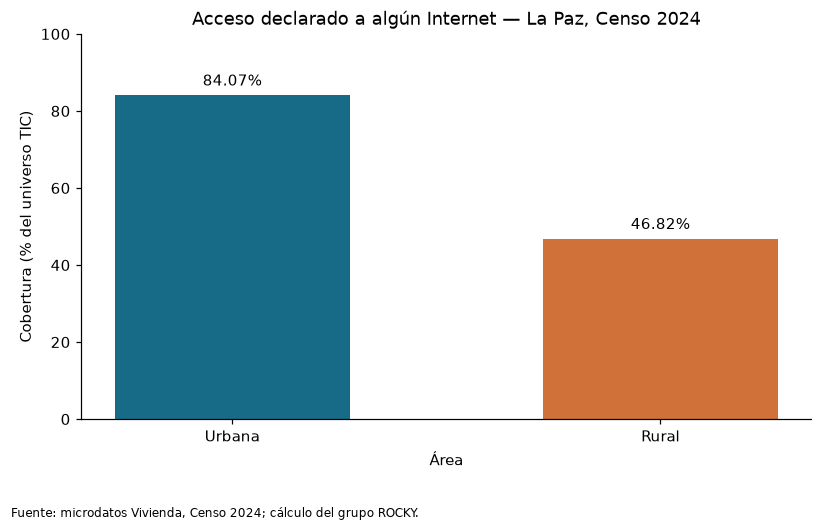

**Hallazgo:** brecha urbano/rural de **37.25 puntos porcentuales**. El rezago rural merece verificación de infraestructura y disponibilidad de servicio.

In [6]:
filas=[]
for c,nombre in [('1','Urbana'),('2','Rural')]:
    grupo=universo.loc[universo.urbrur.eq(c)]
    filas.append({'Área':nombre,'Universo (viviendas)':len(grupo),
                  'Con Internet':int(grupo.v19e_f.eq('1').sum()),
                  'Cobertura (%)':100*grupo.v19e_f.eq('1').mean()})
areas=pd.DataFrame(filas); display(areas.round(2))
fig,ax=plt.subplots(figsize=(7.5,4.8))
barras=ax.bar(areas['Área'],areas['Cobertura (%)'],color=['#176b87','#cf7139'],width=.55)
ax.bar_label(barras,labels=[f'{v:.2f}%' for v in areas['Cobertura (%)']],padding=4)
ax.set(title='Acceso declarado a algún Internet — La Paz, Censo 2024',
       xlabel='Área',ylabel='Cobertura (% del universo TIC)',ylim=(0,100))
fig.text(.01,.01,FUENTE,fontsize=8);fig.tight_layout(rect=[0,.07,1,1]);plt.show()
brecha=areas.iloc[0]['Cobertura (%)']-areas.iloc[1]['Cobertura (%)']
display(Markdown(f'**Hallazgo:** brecha urbano/rural de **{brecha:.2f} puntos porcentuales**. '
                 'El rezago rural merece verificación de infraestructura y disponibilidad de servicio.'))


### Respuesta 5

Se compara el acceso declarado entre área urbana y rural con el mismo denominador
TIC en cada área. La diferencia orienta el diagnóstico territorial; no demuestra
que residir en un área cause el resultado. Se muestran tamaños y unidades.

**Resultado e interpretación:** la cobertura urbana es **84,07%** sobre 664.447 viviendas del universo TIC; la rural es **46,82%** sobre 405.391 viviendas. La brecha es **37,25 puntos porcentuales**. El resultado orienta la revisión de disponibilidad e infraestructura en áreas rurales, sin atribuir causalidad al lugar de residencia.

## 6. ¿Cuál es el target, las clases y el modelo?

In [7]:
motivos=[
 'Diferencias de infraestructura y disponibilidad entre áreas.',
 'Condiciones residenciales asociadas a instalación de conectividad.',
 'Condición para utilizar equipos y servicios digitales.',
 'Equipamiento asociado al uso digital; no revela acceso por sí solo.',
 'Equipamiento telefónico; no equivale a disponer de datos móviles.',
 'Tamaño físico de vivienda; indicador aproximado con categoría superior abierta.',
 'Cantidad de personas y demanda compartida de conectividad.'
]
display(pd.DataFrame({'Variable':predictores,
                     'Descripción':[diccionario[c]['descripcion'] for c in predictores],
                     'Justificación':motivos}))
display(y.value_counts().sort_index().rename('Viviendas').to_frame().rename(index={0:'Sin Internet',1:'Con Internet'}))


,Variable,Descripción,Justificación
0,urbrur,Área Urbana - Rural,Diferencias de infraestructura y disponibilidad entre áreas.
1,v01_tipoviv,1. La vivienda es: (Tipo de vivienda),Condiciones residenciales asociadas a instalación de conectividad.
2,v09_energia,9. De donde proviene la energía eléctrica que usan en la vivienda,Condición para utilizar equipos y servicios digitales.
3,v19c_compu,"19.3. Su hogar tiene: Computadora, laptop o tablet",Equipamiento asociado al uso digital; no revela acceso por sí solo.
4,v19d_celular,19.4. Su hogar tiene: Teléfono celular,Equipamiento telefónico; no equivale a disponer de datos móviles.
5,v13_habitac,"13. Cuántos cuartos o habitaciones ocupan, sin contar baño y cocina",Tamaño físico de vivienda; indicador aproximado con categoría superior abierta.
6,tot_pers,Total personas,Cantidad de personas y demanda compartida de conectividad.


,Viviendas
v19e_f,
Sin Internet,290940
Con Internet,748401


### Respuesta 6

`TIENE_ACCESO_INTERNET` proviene exclusivamente de `v19e_f`: **1 = con Internet,
0 = sin Internet**. El código 9 no se convierte en cero. Se utiliza regresión logística
por su adecuación a un resultado binario y la interpretación de sus coeficientes.
Es la primera iteración, con regularización L2 predeterminada, `max_iter=1000` y
sin pesos de clase. No se afirma una optimización de hiperparámetros que no se realizó.

La selección de variables se justifica antes del ajuste; no se usan identificadores
ni modalidades de Internet como predictores. Celular no equivale a Internet móvil.

**Clases observadas:** 748.401 viviendas con Internet y 290.940 sin Internet. La tabla anterior documenta los siete predictores y su justificación: área, tipo de vivienda, energía, computadora, celular, habitaciones y personas. La elección responde al problema del proyecto y evita utilizar variables que revelarían el target.

## 7. ¿Cómo dividieron los datos y evitaron fuga de información?

In [8]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.20,random_state=SEMILLA,stratify=y)
assert set(X_train.index).isdisjoint(X_test.index)
display(pd.DataFrame({'Conjunto':['Entrenamiento','Prueba'],
                     'Viviendas':[len(y_train),len(y_test)],
                     'Con Internet (%)':[100*y_train.mean(),100*y_test.mean()]}).round(4))
preparacion=ColumnTransformer([
 ('categoricas',Pipeline([('imputar',SimpleImputer(strategy='most_frequent')),
                         ('codificar',OneHotEncoder(handle_unknown='ignore',drop='first',sparse_output=True))]),categoricas),
 ('numericas',SimpleImputer(strategy='median'),numericas)
],sparse_threshold=1.)
modelo=Pipeline([('preparacion',preparacion),('logistica',LogisticRegression(max_iter=1000,solver='lbfgs'))])
modelo.fit(X_train,y_train)
assert modelo.named_steps['logistica'].n_iter_.max()<1000
print('Modelo entrenado sin alcanzar el límite de iteraciones. Imputación y codificación aprendidas en train.')


,Conjunto,Viviendas,Con Internet (%)
0,Entrenamiento,831472,72.0072
1,Prueba,207869,72.0074


Modelo entrenado sin alcanzar el límite de iteraciones. Imputación y codificación aprendidas en train.


### Respuesta 7

Partición **80% entrenamiento / 20% prueba**, estratificada por clase y semilla 777,
igual que la tarea de logística. Se ajustan imputadores, codificación y modelo
exclusivamente con train. El test permanece reservado hasta la evaluación final.
La partición aleatoria evalúa viviendas de la misma población; no acredita
generalización temporal ni geográfica fuera de La Paz.

**Tamaños comprobados:** **831.472 viviendas para entrenamiento** y **207.869 para prueba**. La proporción de viviendas con Internet es aproximadamente 72,01% en ambos conjuntos gracias a la estratificación. Se conserva 80/20 para mantener una evaluación comparable con las tareas de logística y árbol del mismo proyecto, con un test de más de 200 mil viviendas.

## 8. ¿Qué variables destacan y cómo se interpretan?

In [9]:
prep=modelo.named_steps['preparacion']
encoder=prep.named_transformers_['categoricas'].named_steps['codificar']
metadatos=[]
for c,categorias,eliminada in zip(categoricas,encoder.categories_,encoder.drop_idx_):
    referencia=str(categorias[eliminada])
    for i,cat in enumerate(categorias):
        if i==eliminada:continue
        etiqueta=diccionario[c]['categorias'].get(str(cat),str(cat))
        ref=diccionario[c]['categorias'].get(referencia,referencia)
        metadatos.append({'Variable':c,'Categoría':etiqueta,'Referencia':ref})
for c in numericas:metadatos.append({'Variable':c,'Categoría':'Por unidad adicional','Referencia':'No aplica'})
coeficientes=pd.DataFrame(metadatos)
coeficientes['Coeficiente']=modelo.named_steps['logistica'].coef_[0]
coeficientes['Odds ratio']=np.exp(coeficientes['Coeficiente'])
display(coeficientes.round(4))
rural=coeficientes.loc[(coeficientes.Variable=='urbrur')].iloc[0]
display(Markdown(f"**Área rural frente a urbana:** coeficiente {rural['Coeficiente']:.4f}, "
    f"odds ratio **{rural['Odds ratio']:.4f}**. Las odds de acceso rural son "
    f"{rural['Odds ratio']:.3f} veces las urbanas, condicionadas a los demás predictores. "
    'No es una reducción equivalente de probabilidad ni un efecto causal.'))


,Variable,Categoría,Referencia,Coeficiente,Odds ratio
0,urbrur,Rural,Urbana,-1.0132,0.3631
1,v01_tipoviv,"Choza, pahuichi",Casa,0.1553,1.1680
2,v01_tipoviv,Departamento,Casa,0.6642,1.9429
3,v01_tipoviv,Cuarto(s) o habitación(es) suelta(s),Casa,0.2104,1.2341
4,v01_tipoviv,Vivienda improvisada o vivienda móvil,Casa,0.3130,1.3675
5,v01_tipoviv,Establecimiento no destinado para vivienda,Casa,0.0557,1.0573
6,v09_energia,Motor propio (Generador),Servicio público de energía eléctrica,0.1430,1.1537
7,v09_energia,Panel solar,Servicio público de energía eléctrica,-0.3670,0.6928
8,v09_energia,Otro,Servicio público de energía eléctrica,-0.1238,0.8836
9,v09_energia,No tiene,Servicio público de energía eléctrica,-0.3799,0.6839


**Área rural frente a urbana:** coeficiente -1.0132, odds ratio **0.3631**. Las odds de acceso rural son 0.363 veces las urbanas, condicionadas a los demás predictores. No es una reducción equivalente de probabilidad ni un efecto causal.

### Respuesta 8

Se examinan los coeficientes logísticos y sus odds ratios, con la categoría eliminada
por el encoder como referencia. Un coeficiente positivo eleva las log-odds de acceso,
manteniendo constantes los otros predictores. Los coeficientes de variables con
distinta escala no son un ranking directamente comparable de importancia.
Las asociaciones no prueban causalidad ni equivalen a cambios en probabilidad.

**Evidencia e interpretación:** entre los contrastes categóricos binarios destacan no tener celular y no tener computadora, con coeficientes **-3,8395** y **-2,3819** frente a tenerlos. Sus odds ratios son **0,0215** y **0,0924**, respectivamente. El contraste rural frente a urbano tiene coeficiente **-1,0132** y odds ratio **0,3631**.

Por ejemplo, las odds estimadas de acceso de una vivienda rural son 0,3631 veces las de una urbana, manteniendo los otros predictores constantes. Esto no significa una reducción de 63,69% en la probabilidad ni demuestra un efecto causal. No se compara directamente este contraste con el coeficiente por unidad de personas u habitaciones, porque sus escalas difieren.

## 9. ¿Qué desempeño obtuvo en prueba y qué error importa reducir?

,Accuracy,Precisión,Recall,F1,ROC-AUC
Train,0.803081,0.814012,0.941687,0.873208,0.862268
Test,0.803444,0.814425,0.941582,0.873400,0.862540


,Modelo,Accuracy test
0,Siempre clase mayoritaria,0.720074
1,Regresión logística,0.803444


              precision    recall  f1-score   support

Sin Internet       0.75      0.45      0.56     58188
Con Internet       0.81      0.94      0.87    149681

    accuracy                           0.80    207869
   macro avg       0.78      0.69      0.72    207869
weighted avg       0.80      0.80      0.79    207869



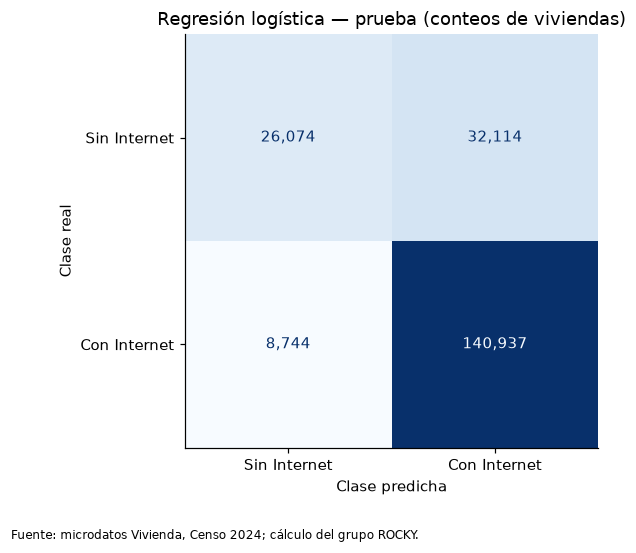

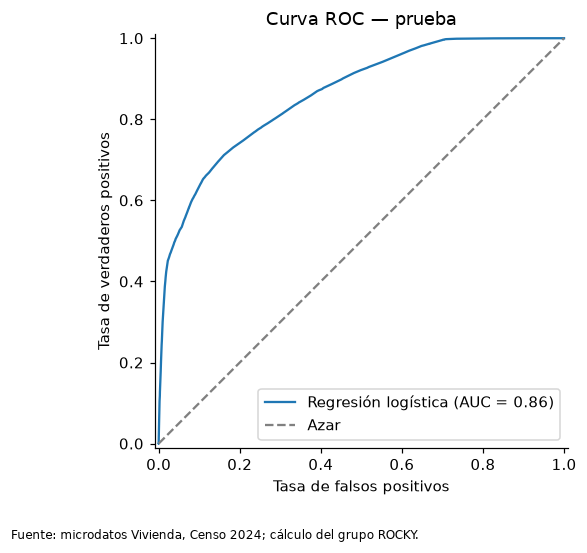

**Interpretación:** accuracy **80.34%**, F1 **0.8734** y ROC-AUC **0.8625**. Supera el baseline en **8.34 puntos porcentuales**. Hay **32,114 falsos positivos** y **8,744 falsos negativos**. El recall de viviendas sin Internet es **44.81%**: la exactitud global oculta una dificultad relevante para localizar la clase sin conexión.

In [10]:
def evaluar(X_e,y_e):
    pred=modelo.predict(X_e);prob=modelo.predict_proba(X_e)[:,1]
    return {'Accuracy':accuracy_score(y_e,pred),'Precisión':precision_score(y_e,pred,zero_division=0),
            'Recall':recall_score(y_e,pred,zero_division=0),'F1':f1_score(y_e,pred,zero_division=0),
            'ROC-AUC':roc_auc_score(y_e,prob)},pred,prob
mtrain,_,_=evaluar(X_train,y_train)
mtest,pred_test,prob_test=evaluar(X_test,y_test)
display(pd.DataFrame({'Train':mtrain,'Test':mtest}).T.round(6))
mayoritaria=int(y_train.mode().iloc[0]);baseline=accuracy_score(y_test,np.full(len(y_test),mayoritaria))
display(pd.DataFrame({'Modelo':['Siempre clase mayoritaria','Regresión logística'],
                     'Accuracy test':[baseline,mtest['Accuracy']]}).round(6))
cm=confusion_matrix(y_test,pred_test,labels=[0,1]);tn,fp,fn,tp=cm.ravel()
assert cm.sum()==len(y_test)
print(classification_report(y_test,pred_test,labels=[0,1],target_names=['Sin Internet','Con Internet'],zero_division=0))
fig,ax=plt.subplots(figsize=(6.5,5))
ConfusionMatrixDisplay(cm,display_labels=['Sin Internet','Con Internet']).plot(ax=ax,cmap='Blues',values_format=',d',colorbar=False)
ax.set(title='Regresión logística — prueba (conteos de viviendas)',xlabel='Clase predicha',ylabel='Clase real')
fig.text(.01,.01,FUENTE,fontsize=8);fig.tight_layout(rect=[0,.06,1,1]);plt.show()
fig,ax=plt.subplots(figsize=(6.5,5))
RocCurveDisplay.from_predictions(y_test,prob_test,ax=ax,name='Regresión logística')
ax.plot([0,1],[0,1],'--',color='gray',label='Azar')
ax.set(title='Curva ROC — prueba',xlabel='Tasa de falsos positivos',ylabel='Tasa de verdaderos positivos');ax.legend()
fig.text(.01,.01,FUENTE,fontsize=8);fig.tight_layout(rect=[0,.06,1,1]);plt.show()
display(Markdown(f"**Interpretación:** accuracy **{100*mtest['Accuracy']:.2f}%**, "
    f"F1 **{mtest['F1']:.4f}** y ROC-AUC **{mtest['ROC-AUC']:.4f}**. "
    f"Supera el baseline en **{100*(mtest['Accuracy']-baseline):.2f} puntos porcentuales**. "
    f"Hay **{fp:,} falsos positivos** y **{fn:,} falsos negativos**. "
    f"El recall de viviendas sin Internet es **{100*tn/(tn+fp):.2f}%**: "
    'la exactitud global oculta una dificultad relevante para localizar la clase sin conexión.'))


### Respuesta 9

Accuracy, precisión, recall y F1 usan el umbral 0,5; ROC-AUC usa probabilidades.
La clase positiva es «con Internet». Para localizar viviendas sin conexión importan
los falsos positivos: viviendas sin Internet clasificadas como conectadas y por ello
potencialmente omitidas en un diagnóstico. Se informa también recall de «sin Internet».
El baseline predice siempre la clase mayoritaria aprendida en train.

**Resultado en prueba:** accuracy **80,34%**, precisión **81,44%**, recall de la clase con Internet **94,16%**, F1 **0,8734** y ROC-AUC **0,8625**. La exactitud del baseline mayoritario es **72,01%**; el modelo la supera en **8,34 puntos porcentuales**.

La matriz de confusión muestra 26.074 verdaderos negativos, **32.114 falsos positivos**, **8.744 falsos negativos** y 140.937 verdaderos positivos. Para localizar viviendas sin conexión importa reducir los falsos positivos: hogares sin Internet que el modelo considera conectados. El recall de la clase sin Internet es solo **44,81%**, lo que limita ese uso práctico pese a la exactitud global.

**Mejora futura comprobable:** definir el costo de omitir una vivienda sin Internet,
seleccionar regularización y umbral mediante validación cruzada dentro de train,
y evaluar después en un nuevo conjunto reservado. Reportar ambos tipos de error,
recall de «sin Internet» y ROC-AUC, frente a esta primera iteración.
Esta propuesta no se presenta como una mejora ya obtenida. Las métricas train/test
cercanas solo descartan una brecha grande en esta partición, no todos los riesgos de sobreajuste.

## 10. ¿Qué visualización explica las decisiones del modelo?

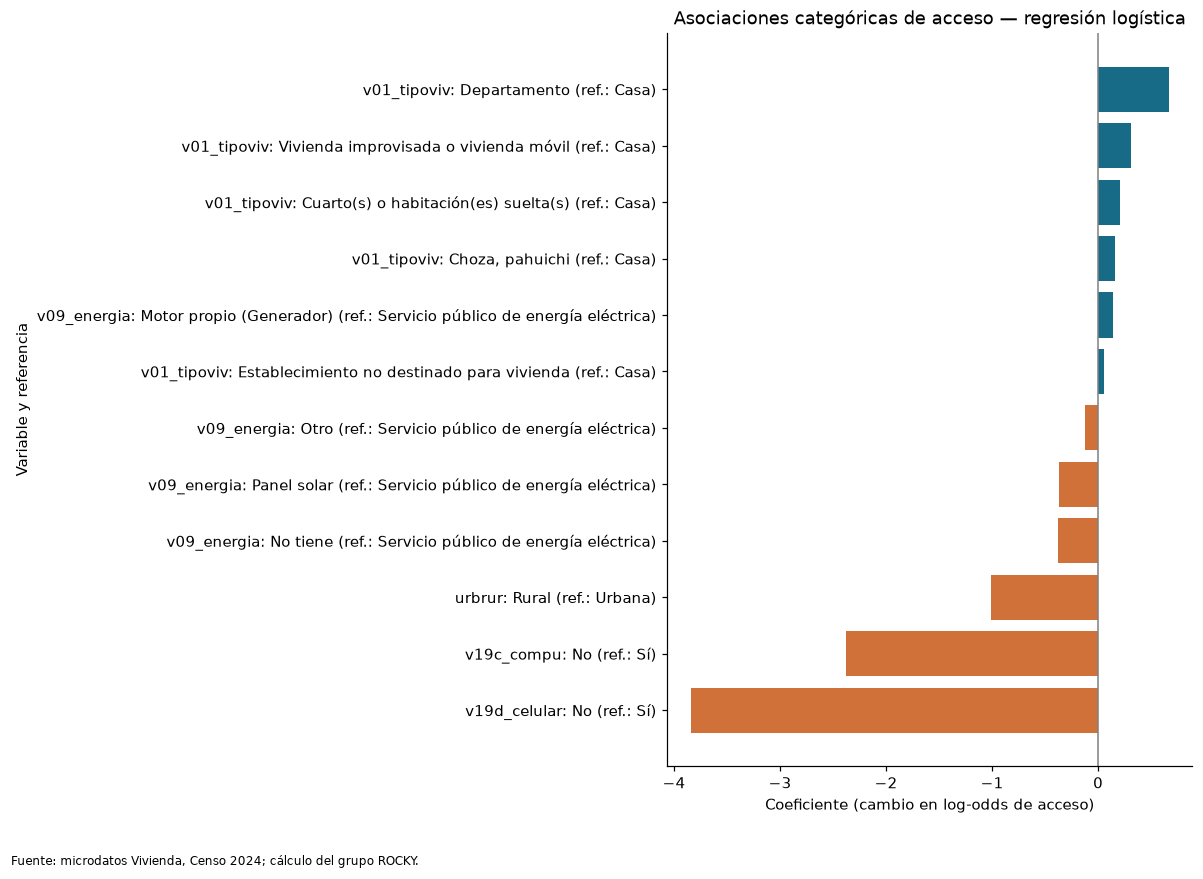

,urbrur,v01_tipoviv,v09_energia,v19c_compu,v19d_celular,v13_habitac,tot_pers
714085,1,1,1,2,1,2,7


,Término,Aporte a log-odds
10,categoricas__v19c_compu_2,-2.3819
12,numericas__v13_habitac,0.0482
13,numericas__tot_pers,0.9689


**Caso de prueba, índice 714085:** probabilidad estimada **86.46%**; predicción **con Internet**, clase real **con Internet**. Esto describe una decisión predictiva, sin explicar causalmente el acceso.

In [11]:
grafico=coeficientes.loc[coeficientes.Variable.isin(categoricas)].copy()
grafico=grafico.sort_values('Coeficiente')
etiquetas=grafico.Variable+': '+grafico['Categoría']+' (ref.: '+grafico.Referencia+')'
fig,ax=plt.subplots(figsize=(11,8))
ax.barh(etiquetas,grafico.Coeficiente,color=np.where(grafico.Coeficiente>=0,'#176b87','#cf7139'))
ax.axvline(0,color='gray',lw=1)
ax.set(title='Asociaciones categóricas de acceso — regresión logística',
       xlabel='Coeficiente (cambio en log-odds de acceso)',ylabel='Variable y referencia')
fig.text(.01,.01,FUENTE,fontsize=8);fig.tight_layout(rect=[0,.05,1,1]);plt.show()
caso=X_test.iloc[[0]]
transformado=prep.transform(caso)
if hasattr(transformado,'toarray'):transformado=transformado.toarray()
aportes=transformado[0]*modelo.named_steps['logistica'].coef_[0]
z=float(modelo.named_steps['logistica'].intercept_[0]+aportes.sum())
p=1/(1+np.exp(-z))
assert np.isclose(p,modelo.predict_proba(caso)[0,1])
display(caso)
display(pd.DataFrame({'Término':prep.get_feature_names_out(),'Aporte a log-odds':aportes})
        .loc[aportes!=0].sort_values('Aporte a log-odds').round(4))
display(Markdown(f'**Caso de prueba, índice {caso.index[0]}:** probabilidad estimada '
                 f'**{p:.2%}**; predicción **{"con Internet" if p>=.5 else "sin Internet"}**, '
                 f'clase real **{"con Internet" if y_test.iloc[0]==1 else "sin Internet"}**. '
                 'Esto describe una decisión predictiva, sin explicar causalmente el acceso.'))


### Respuesta 10

El gráfico muestra coeficientes categóricos, comparables dentro de su codificación,
con las referencias visibles en la tabla anterior. El modelo calcula
$p=1/(1+e^{-z})$, donde $z$ es el intercepto más la suma de coeficiente por predictor
transformado. Predice «con Internet» cuando $p\geq0,5$.
Se muestra también una predicción individual de prueba con sus aportes al puntaje,
para conectar el gráfico con una decisión real del modelo.

**Interpretación de la visualización:** las barras a la izquierda de cero reducen el puntaje estimado de acceso frente a su categoría de referencia; las de la derecha lo aumentan. El gráfico y la tabla permiten relacionar signo, categoría y referencia, sin convertirlos en causas del acceso.

En el caso individual mostrado, el código calcula los aportes reales del modelo, suma el intercepto y aplica la función logística. La comprobación con `predict_proba` confirma que la explicación corresponde a la misma predicción del modelo entrenado. La probabilidad y la clase real quedan visibles en la salida ejecutada.

## Cierre y límites del proyecto
Se observa una brecha de cobertura territorial y el modelo aporta discriminación
frente al baseline. No obstante, el bajo reconocimiento de la clase sin Internet
limita su uso para priorizar viviendas. Las recomendaciones requieren diagnóstico
y una evaluación con costos de error, sin presentar acceso declarado como calidad del servicio.

Limitaciones: respuestas indeterminadas excluidas del target, imputación de predictores,
habitaciones con categoría abierta «8 o más», variables socioeconómicas aproximadas,
partición aleatoria dentro de La Paz y datos de una sola medición censal.
La inferencia corresponde a viviendas del universo definido; no a personas ni a todo Bolivia.


In [12]:
assert len(X)==len(y)==si+no
assert len(X_train)+len(X_test)==len(X)
assert np.isclose(mtest['Accuracy'],(tn+tp)/cm.sum())
assert np.isclose(mtest['F1'],2*tp/(2*tp+fp+fn))
assert len(coeficientes)==len(prep.get_feature_names_out())
assert not set(predictores)&{'v19e_f','v19e_inetfijo','v19f_inetmovil'}
print('Validación final: filtros, partición, métricas, coeficientes y ausencia de predictores de Internet comprobados.')
print('Las diez preguntas tienen respuestas, código y evidencia visible.')


Validación final: filtros, partición, métricas, coeficientes y ausencia de predictores de Internet comprobados.
Las diez preguntas tienen respuestas, código y evidencia visible.
